In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os

PROJECT_ROOT = "/content/drive/MyDrive/pratham"

os.chdir(PROJECT_ROOT)

print(os.getcwd())


/content/drive/MyDrive/pratham


In [4]:
!mkdir -p datasets

In [5]:
%cd datasets

!kaggle datasets download -d fedesoriano/heart-failure-prediction

!unzip -q heart-failure-prediction.zip -d heart_failure

/content/drive/MyDrive/pratham/datasets
Dataset URL: https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction
License(s): ODbL-1.0
heart-failure-prediction.zip: Skipping, found more recently modified local copy (use --force to force download)
replace heart_failure/heart.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: y


In [6]:
!find . -type f

./heart-failure-prediction.zip
./heart_failure/heart.csv


In [7]:
import pandas as pd

df = pd.read_csv("./heart_failure/heart.csv")

print(df.head())
print(df.columns)
print(df.shape)

   Age Sex ChestPainType  RestingBP  Cholesterol  FastingBS RestingECG  MaxHR  \
0   40   M           ATA        140          289          0     Normal    172   
1   49   F           NAP        160          180          0     Normal    156   
2   37   M           ATA        130          283          0         ST     98   
3   48   F           ASY        138          214          0     Normal    108   
4   54   M           NAP        150          195          0     Normal    122   

  ExerciseAngina  Oldpeak ST_Slope  HeartDisease  
0              N      0.0       Up             0  
1              N      1.0     Flat             1  
2              N      0.0       Up             0  
3              Y      1.5     Flat             1  
4              N      0.0       Up             0  
Index(['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS',
       'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope',
       'HeartDisease'],
      dtype='object')
(918, 12)


In [8]:
%cd /content/drive/MyDrive/pratham

/content/drive/MyDrive/pratham


In [9]:
!find /content/drive/MyDrive/pratham/datasets -name "*.csv"

/content/drive/MyDrive/pratham/datasets/heart_failure/heart.csv


In [10]:
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/pratham/datasets/heart_failure/heart.csv")

print(df.shape)
df.head()

(918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


In [12]:
df.isnull().sum()

,0
Age,0
Sex,0
ChestPainType,0
RestingBP,0
Cholesterol,0
FastingBS,0
RestingECG,0
MaxHR,0
ExerciseAngina,0
Oldpeak,0


In [13]:
print(df.columns.tolist())

['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS', 'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope', 'HeartDisease']


In [14]:
!pip install xgboost shap -q

In [15]:
import pandas as pd

df_encoded = pd.get_dummies(
    df,
    columns=[
        "Sex",
        "ChestPainType",
        "RestingECG",
        "ExerciseAngina",
        "ST_Slope"
    ],
    drop_first=True
)

print(df_encoded.shape)
df_encoded.head()

(918, 16)


,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease,Sex_M,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up
0,40,140,289,0,172,0.0,0,True,True,False,False,True,False,False,False,True
1,49,160,180,0,156,1.0,1,False,False,True,False,True,False,False,True,False
2,37,130,283,0,98,0.0,0,True,True,False,False,False,True,False,False,True
3,48,138,214,0,108,1.5,1,False,False,False,False,True,False,True,True,False
4,54,150,195,0,122,0.0,0,True,False,True,False,True,False,False,False,True


In [16]:
from sklearn.model_selection import train_test_split

X = df_encoded.drop("HeartDisease", axis=1)
y = df_encoded["HeartDisease"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

(734, 15)
(184, 15)


In [17]:
from xgboost import XGBClassifier

model = XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)

model.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.05, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=4,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=200,
              n_jobs=None, num_parallel_tree=None, ...)

In [18]:
from sklearn.metrics import accuracy_score, classification_report

preds = model.predict(X_test)

accuracy = accuracy_score(y_test, preds)

print("Accuracy:", accuracy)

print(classification_report(y_test, preds))

Accuracy: 0.8858695652173914
              precision    recall  f1-score   support

           0       0.86      0.89      0.87        82
           1       0.91      0.88      0.90       102

    accuracy                           0.89       184
   macro avg       0.88      0.89      0.88       184
weighted avg       0.89      0.89      0.89       184



In [19]:
import shap

explainer = shap.TreeExplainer(model)

sample = X_test.iloc[:1]

shap_values = explainer.shap_values(sample)

print("Prediction:")
print(model.predict(sample))

print("\nSHAP Values:")
print(shap_values)

Prediction:
[1]

SHAP Values:
[[ 0.0373489   0.02206243  1.0139276  -0.1825025   0.01398267  0.12649295
   0.37718037  0.19096749  0.33991504  0.07967014 -0.04005638  0.01813699
   0.32294008  0.22209841  0.8592014 ]]


In [20]:
import os

os.makedirs(
    "/content/drive/MyDrive/pratham/models",
    exist_ok=True
)

In [21]:
model.save_model(
    "/content/drive/MyDrive/pratham/models/task9_xgboost_heart_model.json"
)

print("Model saved")

Model saved


In [22]:
import os

for root, dirs, files in os.walk("/content/drive/MyDrive/pratham/datasets"):
    if "chest" in root.lower() or "pneumonia" in root.lower():
        print(root)

In [23]:
%cd /content/drive/MyDrive/pratham/datasets

!kaggle datasets download -d paultimothymooney/chest-xray-pneumonia

!unzip -q chest-xray-pneumonia.zip -d chest_xray_pneumonia

/content/drive/MyDrive/pratham/datasets
Dataset URL: https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia
License(s): other
100% 2.29G/2.29G [00:12<00:00, 190MB/s]



In [24]:
!find /content/drive/MyDrive/pratham/datasets/chest_xray_pneumonia -type d | head -20

/content/drive/MyDrive/pratham/datasets/chest_xray_pneumonia
/content/drive/MyDrive/pratham/datasets/chest_xray_pneumonia/chest_xray
/content/drive/MyDrive/pratham/datasets/chest_xray_pneumonia/chest_xray/__MACOSX
/content/drive/MyDrive/pratham/datasets/chest_xray_pneumonia/chest_xray/__MACOSX/chest_xray
/content/drive/MyDrive/pratham/datasets/chest_xray_pneumonia/chest_xray/__MACOSX/chest_xray/test
/content/drive/MyDrive/pratham/datasets/chest_xray_pneumonia/chest_xray/__MACOSX/chest_xray/test/NORMAL
/content/drive/MyDrive/pratham/datasets/chest_xray_pneumonia/chest_xray/__MACOSX/chest_xray/test/PNEUMONIA
/content/drive/MyDrive/pratham/datasets/chest_xray_pneumonia/chest_xray/__MACOSX/chest_xray/train
/content/drive/MyDrive/pratham/datasets/chest_xray_pneumonia/chest_xray/__MACOSX/chest_xray/train/NORMAL
/content/drive/MyDrive/pratham/datasets/chest_xray_pneumonia/chest_xray/__MACOSX/chest_xray/train/PNEUMONIA
/content/drive/MyDrive/pratham/datasets/chest_xray_pneumonia/chest_xray/__M

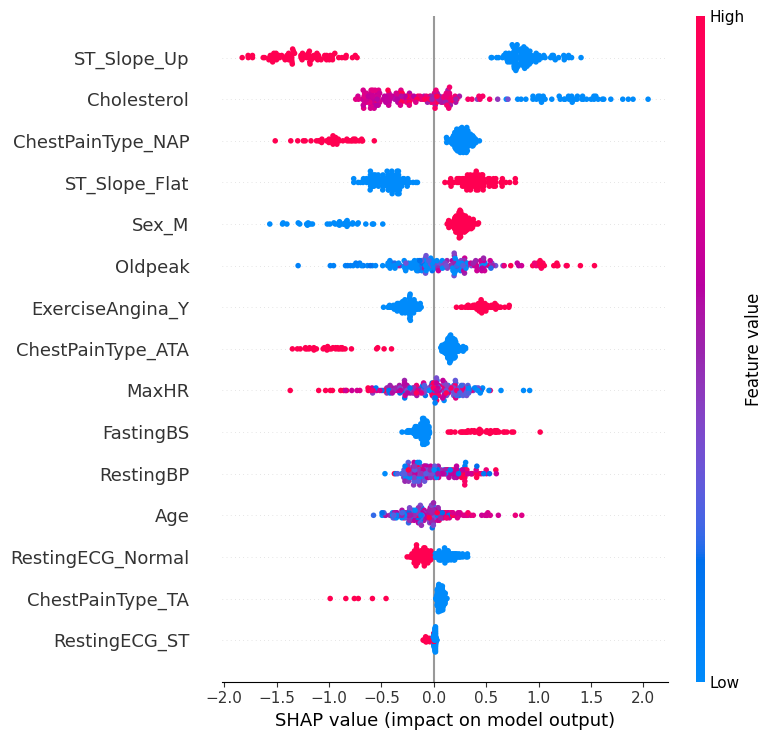

In [25]:
import shap
import matplotlib.pyplot as plt

explainer = shap.TreeExplainer(model)

shap_values = explainer.shap_values(X_test)

shap.summary_plot(
    shap_values,
    X_test,
    show=False
)

plt.savefig(
    "/content/drive/MyDrive/pratham/models/task9_shap_summary.png",
    bbox_inches="tight"
)

plt.show()

In [26]:
import os

os.path.exists(
    "/content/drive/MyDrive/pratham/models/task9_shap_summary.png"
)

True